# 02 · Tissue, bone and heating

Runs the `configs/` examples through the same pipeline as the CLI (`hifu-sim run ...`),
on a coarser grid so the notebook stays fast, and looks at

* how a bone-like inclusion in the beam path distorts the focus, and
* the Pennes temperature rise and CEM43 thermal dose that follow from the absorbed power
  $Q = 2\alpha I$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import hifu_sim as hs
from hifu_sim.config import load_config, run
from hifu_sim.plotting import acoustic_figure, thermal_figure

CONFIGS = Path("..") / "configs"
OUT = Path("_notebook_output")


def coarse(name):
    cfg = load_config(CONFIGS / f"{name}.yaml")
    cfg.grid.spacing = 1.5e-4  # 10 points per wavelength: fine for a preview
    return cfg

In [2]:
runs = {}
for name in ("tissue_layer", "bone_inclusion"):
    out = run(coarse(name), OUT / name, plots=False)
    runs[name] = out
    m = out.metrics
    print(f"{name:15s} peak |p| {m['peak_amplitude_Pa'] / 1e6:.2f} MPa at "
          f"({m['peak_x_m'] * 1e3:.1f}, {m['peak_y_m'] * 1e3:.1f}) mm, "
          f"Tmax {m['temperature_max_C']:.1f} C, CEM43max {m['cem43_max_min']:.3g} min, "
          f"{m['elapsed_s']:.1f} s")

tissue_layer    peak |p| 2.94 MPa at (35.8, 22.0) mm, Tmax 59.3 C, CEM43max 883 min, 2.7 s


bone_inclusion  peak |p| 2.40 MPa at (33.5, 22.4) mm, Tmax 58.1 C, CEM43max 369 min, 2.0 s


## Acoustic field

The bone (c = 2800 m/s, ρ = 1850 kg/m³) has about 3.2 times the acoustic impedance of soft
tissue: a large part of the wave hitting it is reflected (standing-wave fringes in front of
it), the rest is refracted and strongly absorbed, so the focus is weaker and displaced.

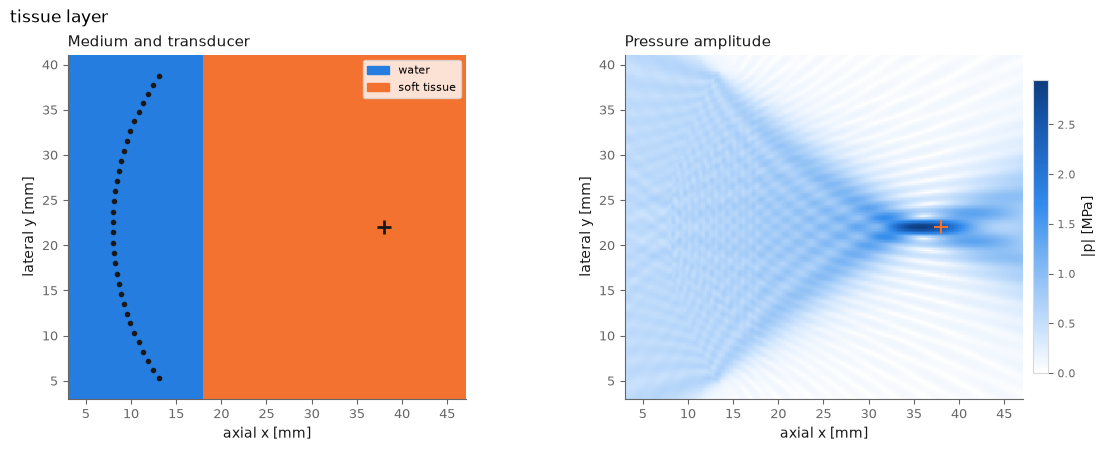

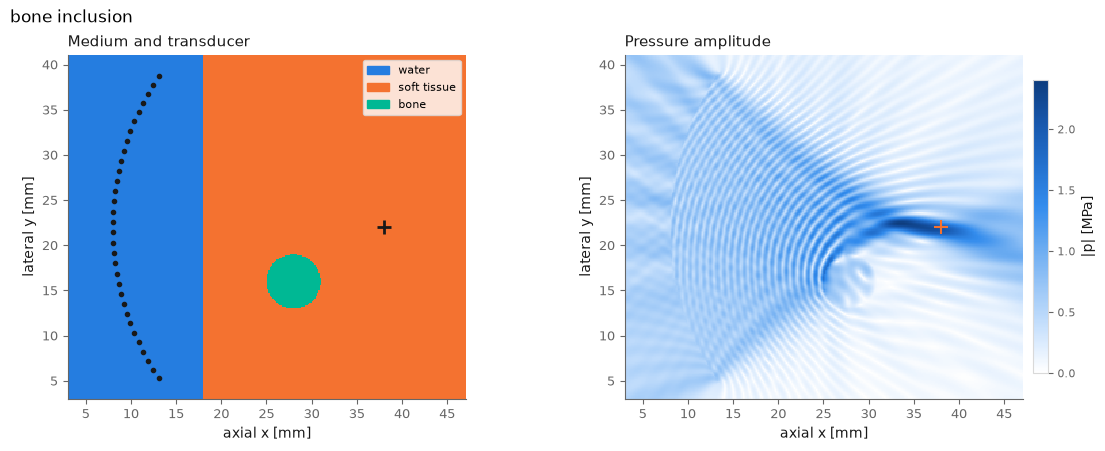

In [3]:
for name, out in runs.items():
    fig = acoustic_figure(out.setup, out.acoustic)
    fig.suptitle(name.replace("_", " "), x=0.01, ha="left", fontsize=12)
    plt.show()

In [4]:
a = runs["tissue_layer"].metrics
b = runs["bone_inclusion"].metrics
print(f"focal peak with bone / without: {b['peak_amplitude_Pa'] / a['peak_amplitude_Pa']:.2f}")
print(f"peak shift: dx = {(b['peak_x_m'] - a['peak_x_m']) * 1e3:+.2f} mm, "
      f"dy = {(b['peak_y_m'] - a['peak_y_m']) * 1e3:+.2f} mm")

focal peak with bone / without: 0.82
peak shift: dx = -2.25 mm, dy = +0.45 mm


## Heating and thermal dose

$\rho C\,\partial_t T = \nabla\cdot(k\nabla T) - w_b c_b (T - T_a) + Q$, followed by
$\mathrm{CEM43} = \sum R^{43 - T}\,\Delta t$ with $R = 0.5$ above 43 °C and 0.25 below.
240 min is a commonly used threshold for thermal necrosis in soft tissue. In the bone case the
hottest point is the bone surface, not the focus: a classic HIFU safety issue.

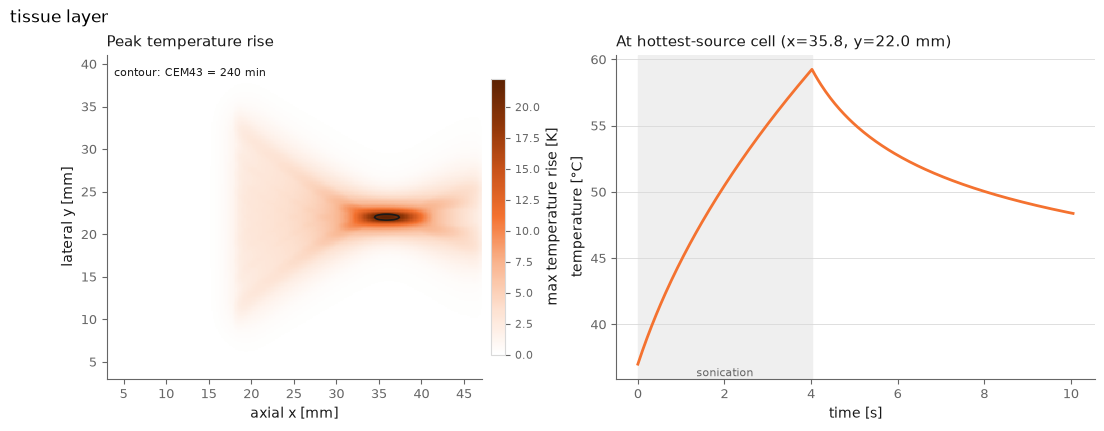

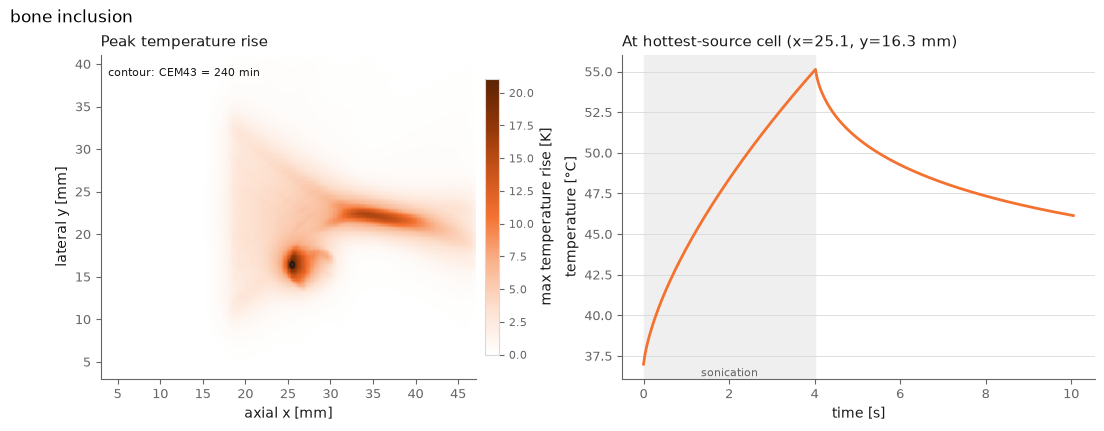

In [5]:
for name, out in runs.items():
    fig = thermal_figure(out.acoustic, out.thermal)
    fig.suptitle(name.replace("_", " "), x=0.01, ha="left", fontsize=12)
    plt.show()

In [6]:
for name, out in runs.items():
    dose = out.thermal.cem43
    cell_area_mm2 = (out.setup.grid.dx * 1e3) ** 2
    lesion = (dose >= hs.thermal.CEM43_THRESHOLD).sum() * cell_area_mm2
    print(f"{name:15s} area with CEM43 >= 240 min: {lesion:.2f} mm^2")

tissue_layer    area with CEM43 >= 240 min: 1.62 mm^2
bone_inclusion  area with CEM43 >= 240 min: 0.25 mm^2


## Saved outputs

`run()` writes the same files as the CLI: an `.npz` with all maps and a JSON with the
configuration and metrics.

In [7]:
data = np.load(OUT / "bone_inclusion" / "bone_inclusion.npz")
sorted(data.files)

['alpha_np_per_m',
 'cem43',
 'density',
 'heat_source',
 'intensity',
 'labels',
 'peak_negative',
 'peak_positive',
 'pml_cells',
 'pressure_amplitude',
 'pressure_phase',
 'probe_temperature',
 'probe_times',
 'sound_speed',
 'temperature_max',
 'x',
 'y']